# ERA5 independent reproduction and timing audit

Uses the ten preserved NetCDF files. Original outputs remain unchanged. See docs/REPRODUCIBILITY_AUDIT.md for interpretation.

In [1]:
from pathlib import Path
import os,sys
root=Path.cwd()
sys.path.insert(0,str(root/'src'))
from reproduce_monsoon import run
inputs=Path(os.environ.get('ERA5_INPUT_DIR',str(root/'data/raw')))
metrics=run(inputs,root/'data/processed',root/'results/reproducibility')

{
  "legacy_trend_slope": 5.957842612121213,
  "legacy_trend_p": 0.5908988814420632,
  "common_window_trend_slope": 5.911544152462122,
  "common_window_trend_p": 0.5940440661075574,
  "common_window_days": 121,
  "empty_days_created_by_legacy_resample": 2189,
  "legacy_resampled_95th": 2.7431910991668693,
  "legacy_observed_utc_95th": 9.01036491394043,
  "corrected_complete_pkt_95th": 9.03042221069336,
  "schema": "Preserved NetCDF4/HDF5 snapshot only; unscaled float32 variables on a fixed 3x3 grid"
}
 year  observed_total_mm  complete_days  missing_rain_hours  full_season_total_mm  complete_day_total_mm wettest_day_date  wettest_day_mm  heavy_rain_days_count  longest_observed_dry_spell_days  mean_complete_day_temp_c
 2016         186.810760            121                   4                   NaN             186.810760       2016-08-27       20.697329                      5                               16                 33.909786
 2017         218.156708            121              

,check,max_abs_difference,tolerance,passed
0,daily_precip_mm,0.000002,0.0001,True
1,daily_temp_c,0.000002,0.0001,True
2,annual_monsoon_total_mm,0.000032,0.0010,True
3,annual_wettest_day_mm,0.000002,0.0001,True
4,annual_heavy_rain_days_count,0.000000,0.0000,True
5,annual_longest_dry_spell_days,0.000000,0.0000,True
6,wettest_dates,0.000000,0.0000,True


,year,observed_total_mm,complete_days,missing_rain_hours,full_season_total_mm,complete_day_total_mm,wettest_day_date,wettest_day_mm,heavy_rain_days_count,longest_observed_dry_spell_days,mean_complete_day_temp_c
0,2016,186.810760,121,4,NaN,186.810760,2016-08-27,20.697329,5,16,33.909786
1,2017,218.156708,121,4,NaN,218.156708,2017-06-28,26.068317,7,18,33.500282
2,2018,84.673935,121,4,NaN,84.673935,2018-07-20,7.900344,0,23,34.014835
3,2019,224.616669,121,4,NaN,224.616669,2019-08-10,22.274441,8,25,34.132736
4,2020,252.345825,121,4,NaN,251.278458,2020-08-31,106.500999,5,26,34.281082
5,2021,53.380226,121,4,NaN,53.368835,2021-07-13,7.157114,0,30,33.863514
6,2022,374.207855,122,0,374.207855,374.207855,2022-07-17,43.437958,11,36,33.007511
7,2023,145.055664,121,4,NaN,143.351715,2023-07-07,22.285250,4,50,33.492283
8,2024,274.651489,121,4,NaN,274.636139,2024-08-17,40.705627,8,25,34.459637
9,2025,190.788437,121,4,NaN,190.788422,2025-09-08,27.139610,7,24,33.614994


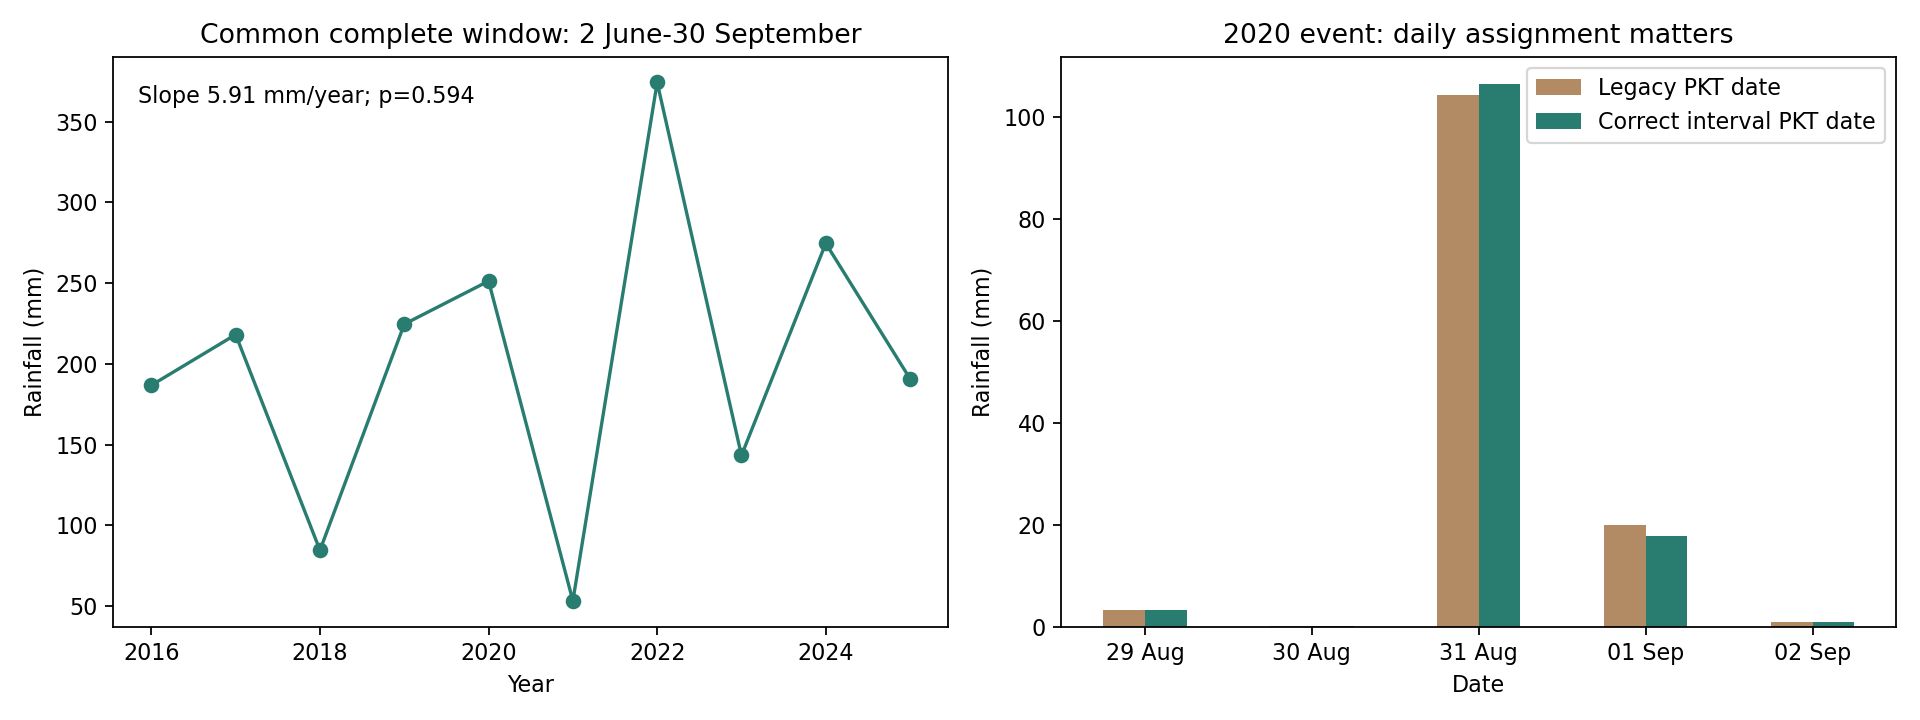

In [2]:
import pandas as pd
from IPython.display import display,Image
display(pd.read_csv(root/'results/reproducibility/legacy_reconciliation.csv'))
display(pd.read_csv(root/'results/reproducibility/annual_coverage_qualified.csv'))
display(Image(filename=str(root/'results/reproducibility/timing_and_common_window.png')))